# Teste iterativo de certificados

Execute as células em ordem. Por padrão, o notebook gera uma prévia de três certificados em uma pasta separada; altere `GENERATE_ALL` para gerar todos.

In [8]:
import sys
from collections import Counter
from pathlib import Path

import pymupdf
from IPython.display import Image, display

current = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (current, *current.parents) if (path / "src/fill_pdf_form").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Abra o notebook dentro do workspace do gerador de certificados.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fill_pdf_form.attendance import load_attendance, write_reports
from fill_pdf_form.certificate_pdf import write_certificates

In [7]:
ACTIVITIES_CSV = PROJECT_ROOT / "examples/atividades.csv"
ATTENDEES_CSV = PROJECT_ROOT / "examples/checkins.csv"
TEMPLATE = PROJECT_ROOT / "template.pdf"
OUTPUT_DIR = PROJECT_ROOT / "generated-certificates/notebook-preview"
GENERATE_ALL = False
MAX_CERTIFICATES = 3

In [9]:
recipients, non_recipients, certificate_jobs = load_attendance(
    ACTIVITIES_CSV, ATTENDEES_CSV
)
print(f"Elegíveis: {len(recipients)} | não elegíveis: {len(non_recipients)}")
print(f"Motivos de elegibilidade: {Counter(row['motivo'] for row in recipients)}")
print(f"Atividades com certificados: {len({row['atividade_id'] for row in recipients})}")

Elegíveis: 3 | não elegíveis: 2
Motivos de elegibilidade: Counter({'check_in': 1, 'assinado': 1, 'check_in;assinado': 1})
Atividades com certificados: 2


In [10]:
selected_jobs = (
    certificate_jobs if GENERATE_ALL else certificate_jobs[:MAX_CERTIFICATES]
)
selected_filenames = {filename for _, filename in selected_jobs}
selected_recipients = [
    row for row in recipients if row['arquivo_certificado'] in selected_filenames
]
write_reports(OUTPUT_DIR, selected_recipients, non_recipients)
print(f"Certificados selecionados para esta prévia: {len(selected_jobs)}")

Certificados selecionados para esta prévia: 3


In [11]:
generated_files = write_certificates(TEMPLATE, OUTPUT_DIR, selected_jobs)
combined_pdf = OUTPUT_DIR / "certificates-all.pdf"
if selected_jobs:
    with pymupdf.open(combined_pdf) as combined:
        assert len(combined) == len(selected_jobs)
        print(f"PDF combinado validado: {len(combined)} páginas")
print(f"Relatórios e PDFs de teste: {OUTPUT_DIR}")
generated_files

PDF combinado validado: 3 páginas
Relatórios e PDFs de teste: /home/ana/Projects/fill-pdf-form-2/generated-certificates/notebook-preview


[PosixPath('/home/ana/Projects/fill-pdf-form-2/generated-certificates/notebook-preview/20261020-TER-09-AB12CD-abertura-do-evento-lia_exemplo.pdf'),
 PosixPath('/home/ana/Projects/fill-pdf-form-2/generated-certificates/notebook-preview/20261020-TER-09-AB12CD-abertura-do-evento-beto_exemplo.pdf'),
 PosixPath('/home/ana/Projects/fill-pdf-form-2/generated-certificates/notebook-preview/20261020-TER-11-EF34GH-oficina-de-dados-dani_exemplo.pdf'),
 PosixPath('/home/ana/Projects/fill-pdf-form-2/generated-certificates/notebook-preview/certificates-all.pdf')]

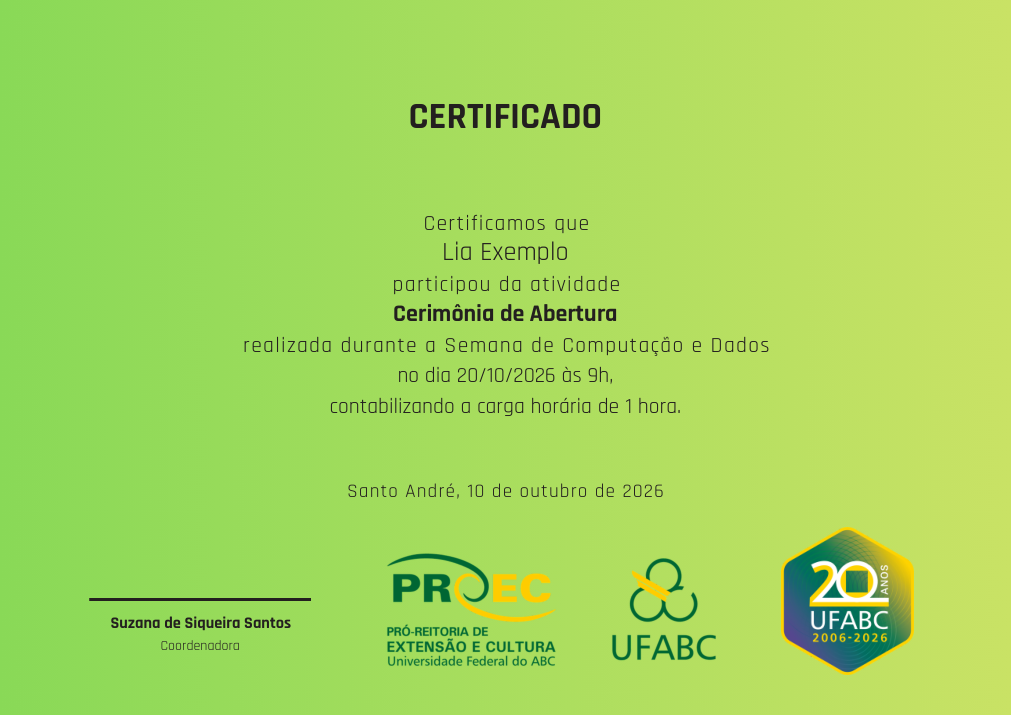

In [12]:
individual_pdfs = [
    path for path in generated_files if path.name != "certificates-all.pdf"
]
if individual_pdfs:
    with pymupdf.open(individual_pdfs[0]) as certificate:
        preview = certificate[0].get_pixmap(matrix=pymupdf.Matrix(1.2, 1.2))
        display(Image(data=preview.tobytes("png")))